# EDA и feature engineering

Основной ноутбук проекта. Разделы 1–3: структура и качество всего датасета,
нули, распределения и связи. Разделы 4–5: подробный анализ **одного маршрута**,
выбранного переменной `ROUTE_ID`. Раздел 6: календарь, лаги, разности,
скользящие статистики, пример признаков train и признаки validation/test.

Данные загружаются один раз. `history` — вся размеченная история,
`train` и `val` получены делением первых 80% истории в пропорции 85/15.
`test` — последние 20% с известными ответами. `submission` содержит будущие строки соревнования. `ROUTE_ID` общий для разбора временного ряда и примера FE.
Папка EDA — `artifacts/eda/`, признаки — `artifacts/features/`.

Функции диагностики находятся в [time_series_analysis.py](time_series_analysis.py),
генерации признаков — в [feature_engineering.py](feature_engineering.py).
Массовая диагностика временных рядов запускается отдельно; Run All её не выполняет.
FE для проверочных срезов и submission рассчитывается для всех маршрутов.

Запуск: `uv sync`, Python из `.venv`, **Restart Kernel → Run All**.

In [1]:
import os
from pathlib import Path

os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".mplconfig"))

import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, NullFormatter
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.seasonal import STL
from IPython.display import display

from time_series_analysis import (
    prepare_series, stationarity_tests, fourier_analysis, wavelet_analysis,
    stl_candidates, stl_search, trend_shape, trend_label,
    seasonal_features, season_label, profile_mean,
)

plt.rcParams.update({"figure.dpi": 100, "font.family": "DejaVu Sans",
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 24)
pd.set_option("display.max_rows", 30)
def plain_number(value, position=None):
    return np.format_float_positional(value, precision=8, fractional=False, trim="-")


def plain_axes(fig):
    for ax in fig.axes:
        for axis in [ax.xaxis, ax.yaxis]:
            if isinstance(axis.get_major_locator(), mdates.DateLocator):
                continue
            axis.set_major_formatter(FuncFormatter(plain_number))
            axis.set_minor_formatter(NullFormatter())
            axis.get_offset_text().set_visible(False)


pd.set_option("display.float_format", plain_number)
np.set_printoptions(formatter={"float_kind": plain_number})
plt.rcParams["axes.formatter.useoffset"] = False
plt.rcParams["axes.formatter.use_mathtext"] = False

In [2]:
ROOT = Path.cwd()
if not (ROOT / "data/train_solo_track.parquet").exists():
    raise FileNotFoundError("Запустите ноутбук из корня проекта с папкой data")
OUT = ROOT / "artifacts/eda"
OUT.mkdir(parents=True, exist_ok=True)
TARGET = "target_1h"
STATUSES = [f"status_{i}" for i in range(1, 7)]
VALUES = STATUSES + [TARGET]
STEP = pd.Timedelta(minutes=30)

versions = {name: importlib.metadata.version(name) for name in
            ["numpy", "pandas", "pyarrow", "matplotlib", "scipy", "statsmodels", "PyWavelets"]}
display(pd.Series(versions, name="Версия"))

numpy           2.5.4
pandas          3.1.1
pyarrow        26.0.1
matplotlib     3.11.2
scipy          1.18.1
statsmodels    0.15.0
PyWavelets     1.10.0
Name: Версия, dtype: str

## 1. Загрузка, структура и качество

По описанию кейса `route_id` обозначает маршрут, `timestamp` — момент наблюдения.
`status_1`–`status_3` — обработка товаров на текущем складе за последние **30 минут**;
`status_4`–`status_6` — обработка на предыдущем складе за последние **30 минут**.
`target_1h` — отгрузка по маршруту за последний **час**.
Соседние часовые окна перекрываются: это учитываем при интерпретации автокорреляции.

Ограничение 25 октября из старого ноутбука относилось к проверке прогноза.
Здесь описательная EDA использует весь доступный train; submission проверяем отдельно.

In [ ]:
history = pd.read_parquet(ROOT / "data/train_solo_track.parquet")
submission = pd.read_parquet(ROOT / "data/test_solo_track.parquet")
for name, frame in [("history", history), ("submission", submission)]:
    print(f"{name}: {frame.shape[0]:,} строк × {frame.shape[1]} столбцов")
    display(frame.head())

### 1.1. Разбиение и экспорт CSV

Последние 20% временных точек образуют test. Предшествующие 80% делим по времени на train и val в пропорции 85/15. Одни и те же границы применяются ко всем маршрутам. Для обучения сохраняем размеченную историю без строк с пропусками в одном CSV. В нём есть идентификатор части и исходные показатели, из которых каждый ноутбук строит признаки своего горизонта.

In [ ]:
import data_split as ds

SPLIT_OUT = ROOT / "artifacts/splits"
dataset = ds.export_labeled_history(history, SPLIT_OUT / "history.csv")
train, val, test = [dataset.loc[dataset.split.eq(name)].drop(columns="split")
                    for name in ("train", "val", "test")]
display(ds.split_summary(train, val, test))
print("Удалено строк с пропусками:", len(history) - len(dataset))
del dataset

split,rows,routes,timestamps,first_timestamp,last_timestamp
train,3148000,1000,3148,2025-07-28 00:00:00,2025-10-01 13:30:00
val,556000,1000,556,2025-10-01 14:00:00,2025-10-13 03:30:00
test,926000,1000,926,2025-10-13 04:00:00,2025-11-01 10:30:00


Удалено строк с пропусками: 0


In [ ]:
history.info()
submission.info()

In [ ]:
display(history.describe(include="all").T)
display(submission.describe(include="all").T)

In [ ]:
quality_tables = []
for name, frame in [("history", history), ("submission", submission)]:
    quality = pd.DataFrame({
        "dataset": name,
        "dtype": frame.dtypes.astype(str),
        "missing_count": frame.isna().sum(),
        "missing_share": frame.isna().mean(),
        "unique_non_null": frame.nunique(),
        "repeated_non_null": frame.notna().sum() - frame.nunique(),
    })
    quality.index.name = "feature"
    quality_tables.append(quality.reset_index())
column_quality = pd.concat(quality_tables, ignore_index=True)
display(column_quality)
print("Повторы значений — наблюдения сверх первого непустого вхождения; это не обязательно ошибка.")

In [ ]:
duplicate_summary = pd.DataFrame([
    {"dataset": name, "full_duplicate_excess": frame.duplicated().sum(),
     "key_duplicate_excess": frame.duplicated(["route_id", "timestamp"]).sum()}
    for name, frame in [("history", history), ("submission", submission)]
])
display(duplicate_summary)
value_quality = pd.DataFrame({
    "negative_count": history[VALUES].lt(0).sum(),
    "infinite_count": np.isinf(history[VALUES]).sum(),
})
display(value_quality)
if history[["route_id", "timestamp"]].isna().any().any():
    raise ValueError("Пропуски в ключе: временные ряды нельзя восстановить однозначно")
if duplicate_summary.key_duplicate_excess.any():
    display(history.loc[history.duplicated(["route_id", "timestamp"], keep=False)].head(20))
    raise ValueError("Повторы ключа route/time: требуется явное решение, записи не усредняются")
if value_quality.infinite_count.any():
    raise ValueError("Найдены бесконечные значения: требуется исследовать источник")

In [ ]:
def time_coverage(frame):
    rows = []
    common_start, common_end = frame.timestamp.min(), frame.timestamp.max()
    common_grid = pd.date_range(common_start, common_end, freq=STEP)
    for route, group in frame.groupby("route_id", sort=True):
        times = pd.DatetimeIndex(group.timestamp).sort_values()
        own_grid = pd.date_range(times.min(), times.max(), freq=STEP)
        gaps = own_grid.difference(times)
        differences = times.to_series().diff().dropna()
        rows.append({"route_id": route, "first_timestamp": times.min(),
                     "last_timestamp": times.max(), "observations": len(times),
                     "missing_inside": len(gaps),
                     "missing_common_grid": len(common_grid.difference(times)),
                     "irregular_intervals": int(differences.ne(STEP).sum()),
                     "off_grid": int((times != times.floor("30min")).sum()),
                     "first_missing": gaps.min() if len(gaps) else pd.NaT})
    return pd.DataFrame(rows)

train_time = time_coverage(history)
submission_time = time_coverage(submission)
display(pd.DataFrame([
    {"dataset": name, "first": frame.timestamp.min(), "last": frame.timestamp.max(),
     "routes": frame.route_id.nunique(), "rows": len(frame)}
    for name, frame in [("history", history), ("submission", submission)]
]))
display(train_time.describe(include="all").T)
display(train_time.loc[train_time.missing_common_grid.gt(0) | train_time.off_grid.gt(0)])
print("Маршруты только в train:", sorted(set(history.route_id) - set(submission.route_id)))
print("Маршруты только в submission:", sorted(set(submission.route_id) - set(history.route_id)))
transition = submission_time.set_index("route_id")[["first_timestamp"]].join(
    train_time.set_index("route_id")[["last_timestamp"]])
transition["gap"] = transition.first_timestamp - transition.last_timestamp
display(transition.gap.value_counts().rename("routes"))
if train_time.off_grid.any():
    raise ValueError("Есть наблюдения вне получасовой сетки")

**Качество данных.** В размеченной истории 4,630,000 строк и 1,000 маршрутов. Пропущено значений: 0; дубликатов ключа: 0; пропущенных точек внутри маршрутов: 0. История: 2025-07-28 00:00:00 — 2025-11-01 10:30:00. Повторы отдельных значений ожидаемы для целочисленных объёмов. Поведение и распределения ниже исследуются на всей истории.

## 2. Нули и описательная статистика

Долю нулей считаем среди непустых значений. Между маршрутами каждый маршрут имеет
одинаковый вес; отсутствующие наблюдения нулями не считаются.

In [10]:
zero_table = pd.DataFrame({
    "zero_count": history[VALUES].eq(0).sum(),
    "non_null_count": history[VALUES].count(),
})
zero_table["zero_share"] = zero_table.zero_count / zero_table.non_null_count
zero_table.index.name = "feature"
display(zero_table)

,zero_count,non_null_count,zero_share
feature,,,
status_1,11447,4630000,0.0024723542
status_2,9580,4630000,0.0020691145
status_3,357890,4630000,0.077298056
status_4,0,4630000,0
status_5,0,4630000,0
status_6,4817,4630000,0.0010403888
target_1h,69841,4630000,0.015084449


In [11]:
route_zero = history[VALUES].eq(0).groupby(history.route_id).sum().div(
    history.groupby("route_id")[VALUES].count())
zero_across_routes = route_zero.agg(["min", "mean", "median", "max"]).T
zero_across_routes.index.name = "feature"
display(zero_across_routes)

,min,mean,median,max
feature,,,,
status_1,0,0.0024723542,0,0.14816415
status_2,0,0.0020691145,0,0.093520518
status_3,0,0.077298056,0.036609071,0.57667387
status_4,0,0,0,0
status_5,0,0,0,0
status_6,0,0.0010403888,0,0.17969762
target_1h,0,0.015084449,0.0021598272,0.23239741


In [12]:
feature_summary = history[VALUES].agg(["nunique", "mean", "median", "std"]).T
feature_summary["pearson_target"] = history[VALUES].corrwith(history[TARGET], method="pearson")
feature_summary["spearman_target"] = history[VALUES].corrwith(history[TARGET], method="spearman")
feature_summary.index.name = "feature"
display(feature_summary)

,nunique,mean,median,std,pearson_target,spearman_target
feature,,,,,,
status_1,272,22.676771,21,13.041413,0.48759636,0.52398394
status_2,243,22.858541,21,12.85778,0.50652743,0.53451408
status_3,260,22.856843,19,19.439994,0.45090207,0.478247
status_4,315655,119215.63,109912,59825.655,0.43117711,0.47723057
status_5,1463128,701978.89,618836,421306.31,0.36968744,0.4217568
status_6,82051,3344.6073,162,10048.168,0.10445992,0.2424644
target_1h,692648,261242.14,235769,169082.59,1,1


In [13]:
most_zero = zero_table.zero_share.idxmax()
strongest = feature_summary.loc[STATUSES, "spearman_target"].abs().idxmax()

**Нули и связи.** Наибольшая общая доля нулей у `status_3`: 7.7%. У таргета: 1.5%; между маршрутами диапазон 0.0%–23.2%. Наибольшая абсолютная ранговая связь с таргетом у `status_2` (Spearman 0.535). Это одновременная связь по всем строкам: она может отражать масштаб маршрутов и сама по себе не доказывает полезность для прогноза.

## 3. Распределения и боксплоты

По X — объём статуса, по левой Y — число наблюдений. Оранжевая линия на правой Y —
медиана таргета среди строк соответствующего интервала статуса. Это **не** плотность
распределения таргета. Разрыв линии означает пустой интервал.
Слева весь диапазон, справа увеличение до q99; исходные значения не удаляем.
Все гистограммы и квантили строятся по полным данным.

In [14]:
def distribution_plot(column):
    values = history[column].dropna()
    upper = values.quantile(.99)
    fig, axes = plt.subplots(2, 2, figsize=(14, 7), height_ratios=[3, 1])
    for j, limit in enumerate([values.max(), upper]):
        high = max(float(limit), float(values.min()) + 1)
        bins = np.linspace(float(values.min()), high, 51)
        if values.nunique() <= 50:
            bins = np.arange(values.min() - .5, high + 1, 1)
        bins[-1] = np.nextafter(bins[-1], np.inf)
        ax = axes[0, j]
        ax.hist(values, bins=bins, color="#4682b4", alpha=.75)
        ax.set(xlabel=column, ylabel="Число наблюдений")
        if column == TARGET:
            ax.axvline(values.median(), color="#d76b15", label="Медиана таргета")
            ax.legend()
        else:
            intervals = pd.cut(history[column], bins=bins, include_lowest=True, right=False)
            medians = history[TARGET].groupby(intervals, observed=False).median()
            centers = (bins[:-1] + bins[1:]) / 2
            right = ax.twinx()
            right.plot(centers, medians.to_numpy(), color="#d76b15", lw=1.8,
                       label="Медиана target по интервалу")
            right.set_ylabel("Медиана target_1h", color="#d76b15")
            right.legend(fontsize=8, loc="upper right")
        hidden = values.gt(limit).mean()
        ax.set_title("Весь диапазон" if j == 0 else f"До q99; за правой границей {hidden:.2%}")
        axes[1, j].boxplot(values, orientation="horizontal", showfliers=(j == 0),
                           flierprops={"markersize": 1, "alpha": .15})
        axes[1, j].set(xlabel=column, yticks=[])
        if j == 1:
            axes[1, j].set_xlim(values.min() - .5, high)
    fig.suptitle(column)
    plain_axes(fig)
    fig.tight_layout()
    fig.savefig(OUT / f"distribution_{column}.png", dpi=130)
    plt.show()
    plt.close(fig)

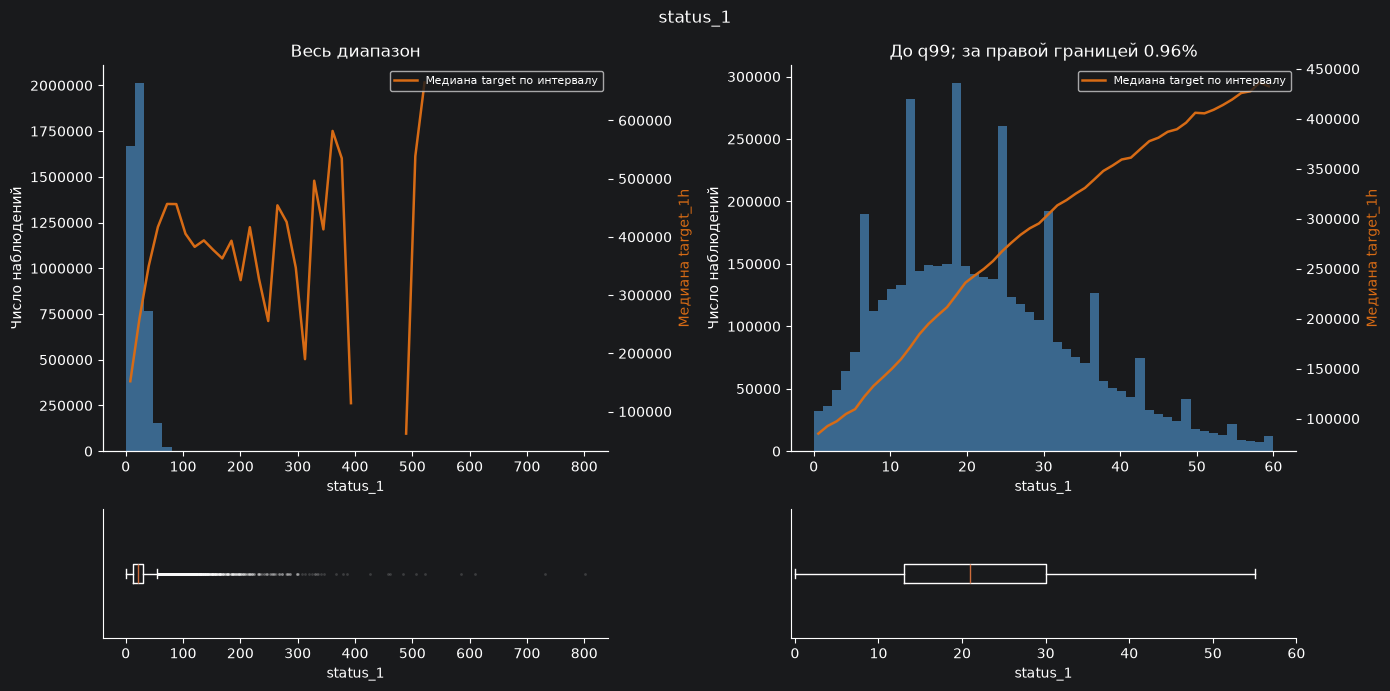

In [15]:
distribution_plot("status_1")

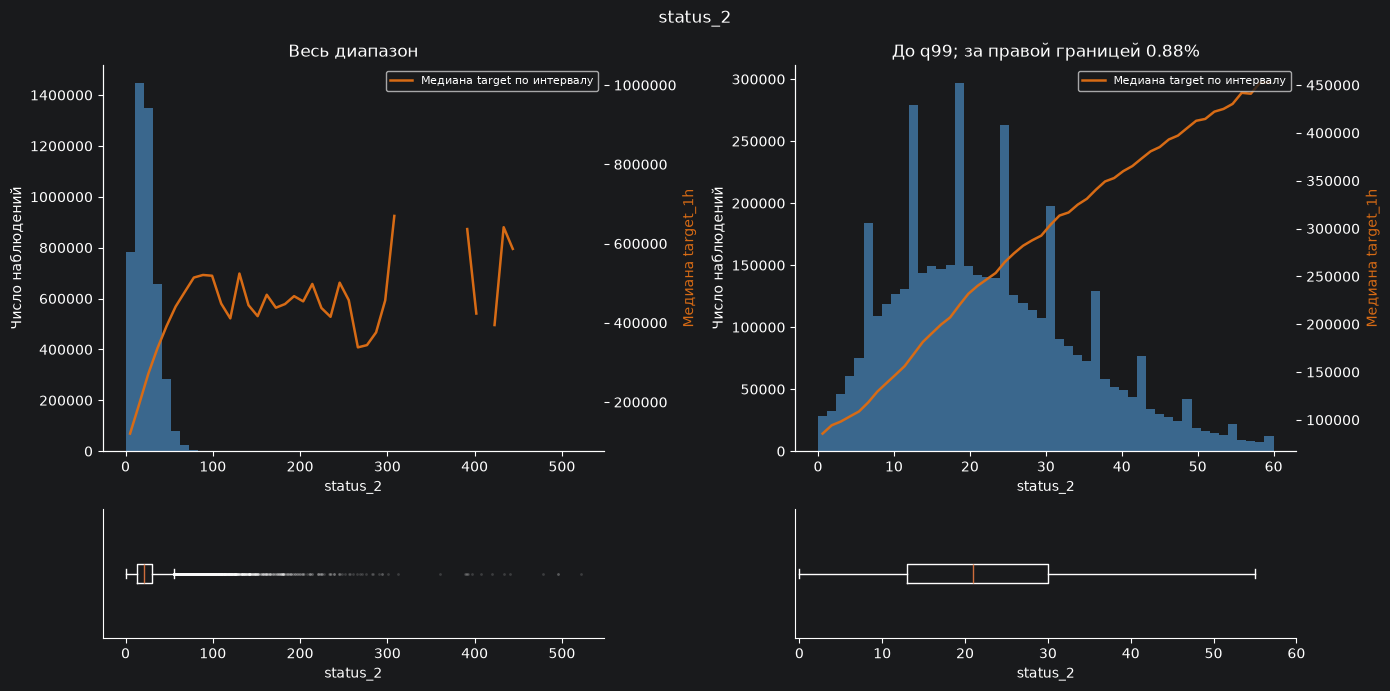

In [16]:
distribution_plot("status_2")

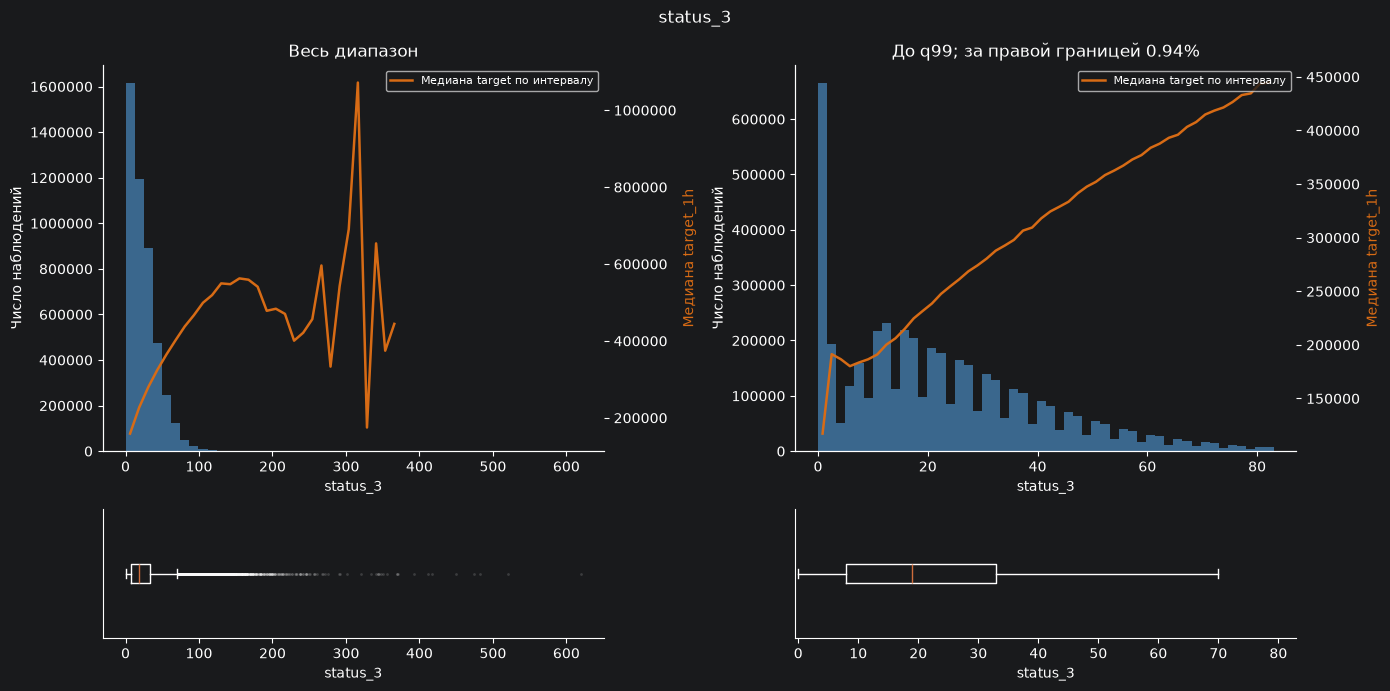

In [17]:
distribution_plot("status_3")

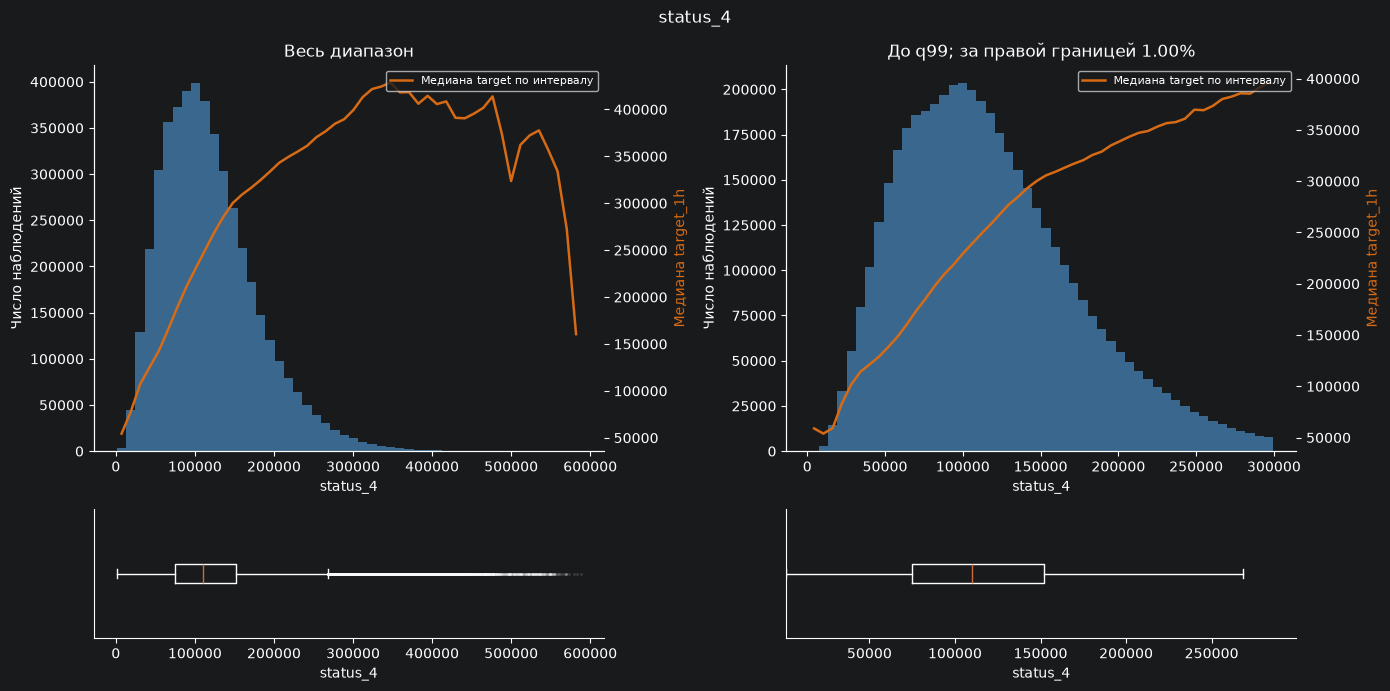

In [18]:
distribution_plot("status_4")

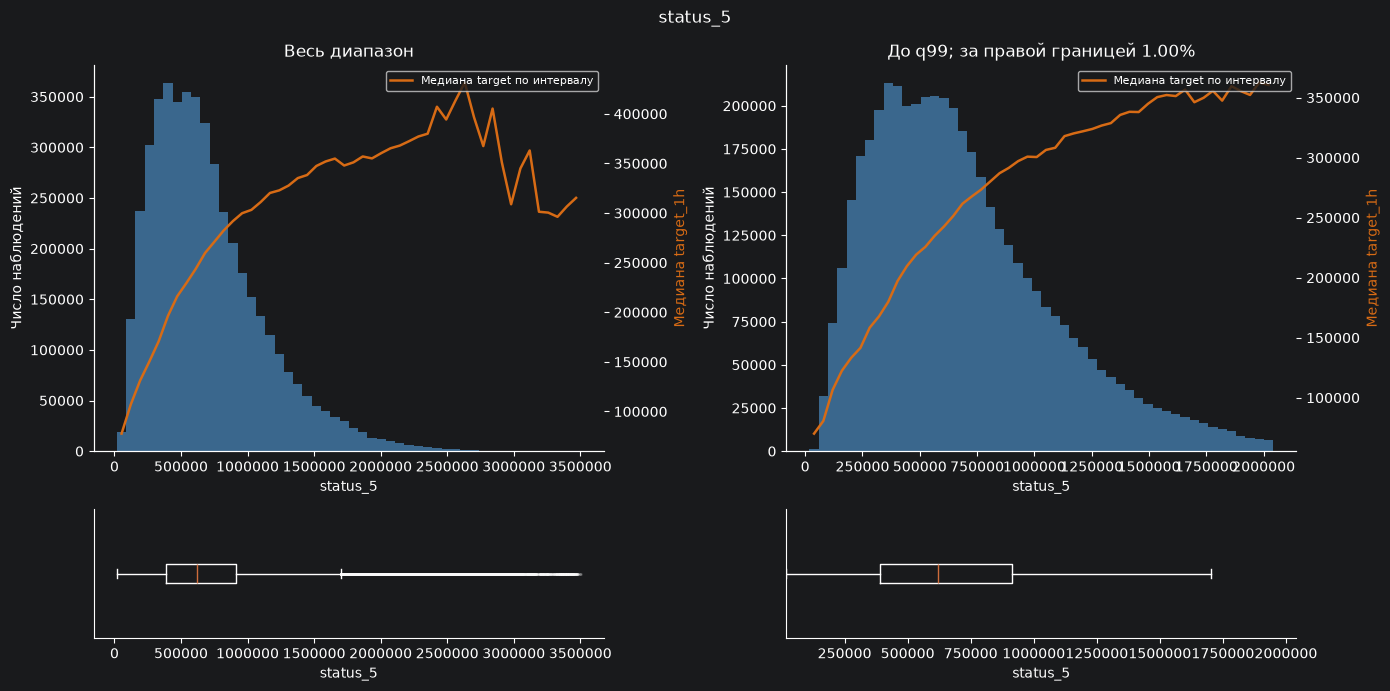

In [19]:
distribution_plot("status_5")

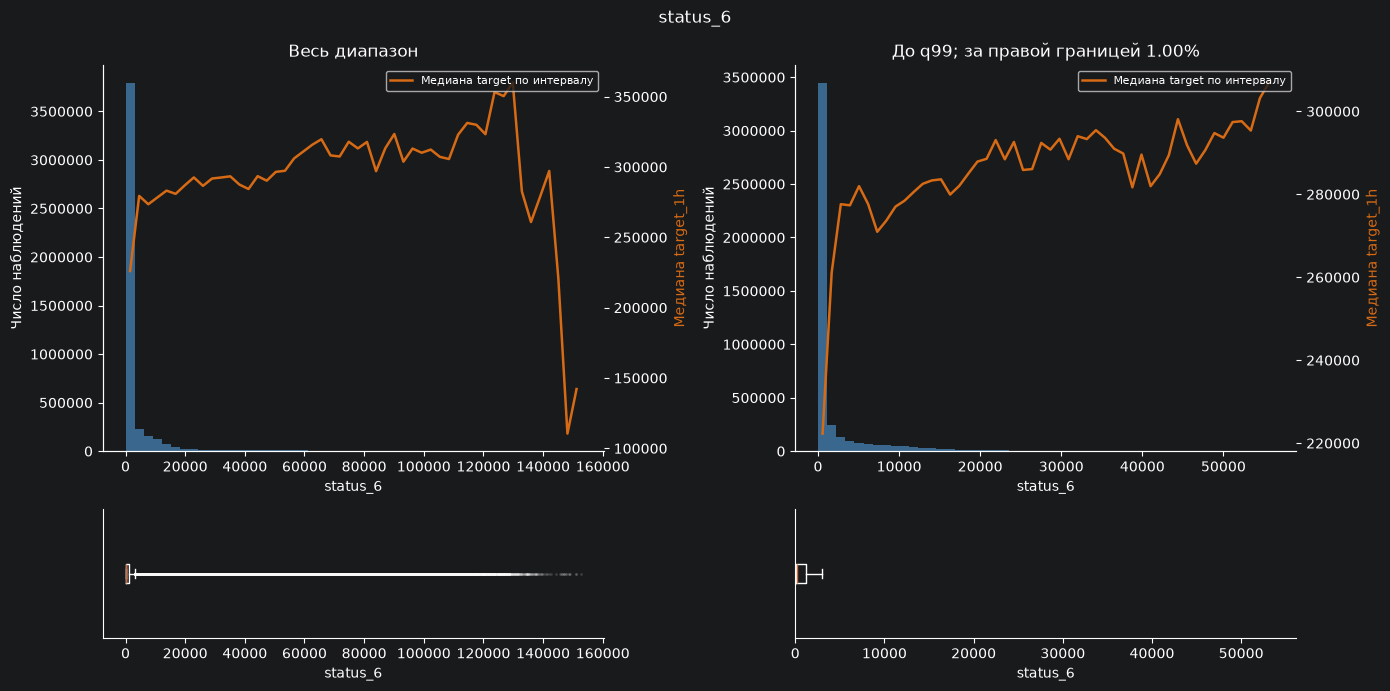

In [20]:
distribution_plot("status_6")

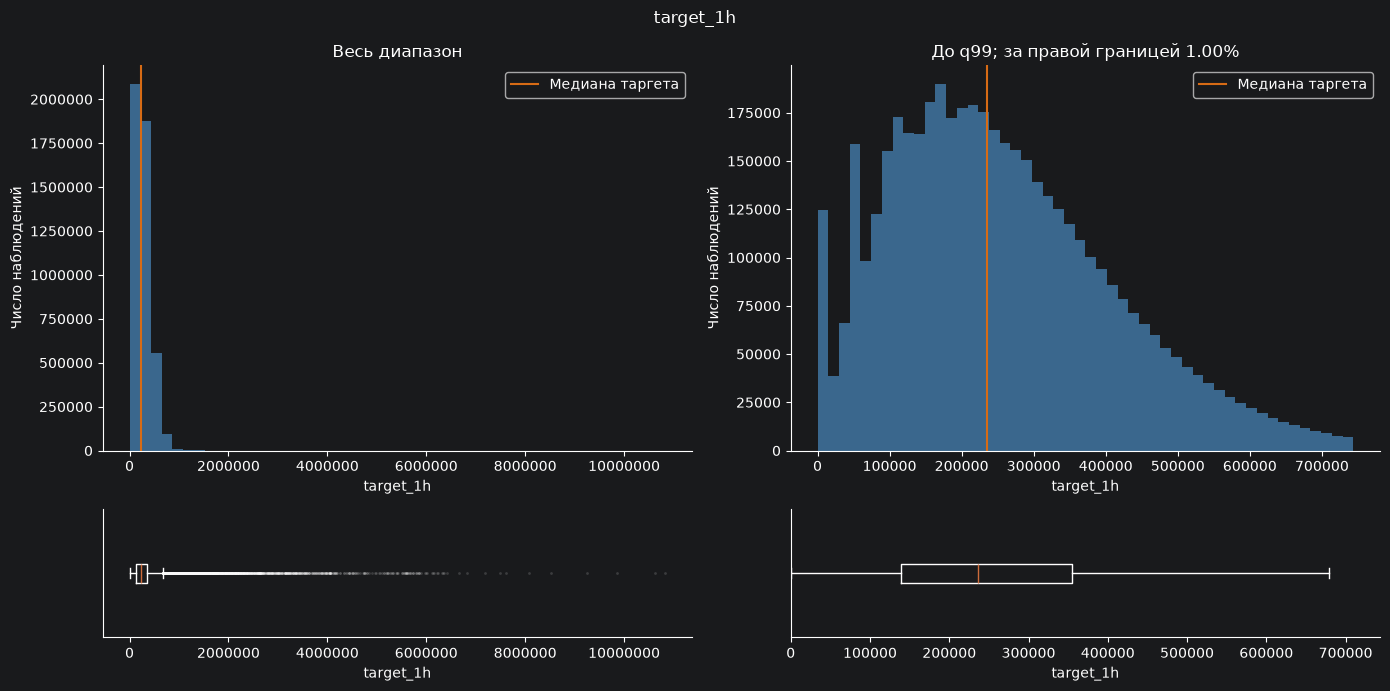

In [21]:
distribution_plot("target_1h")

In [22]:
tails = history[VALUES].quantile([.5, .95, .99, 1]).T
tails.columns = ["q50", "q95", "q99", "max"]
display(tails)

,q50,q95,q99,max
status_1,21,46,60,802
status_2,21,46,60,522
status_3,19,60,83,620
status_4,109912,232197.05,299532.01,587938
status_5,618836,1527944.1,2041425,3503114
status_6,162,16653,56190.01,152739
target_1h,235769,564384,743427.01,10831337


**Чтение графиков.** Длинный правый хвост и точки за усами боксплота не означают ошибку: это могут быть реальные пики отгрузки. Сравнивайте основной диапазон и увеличение. Линия медианы описывает условную связь со статусом; при редких больших значениях она менее устойчива.

## 4. Один маршрут для примера

По умолчанию выбран **644**: его средний объём близок к медианному среди маршрутов.
Для другого примера измените только `ROUTE_ID` и выполните разделы ниже заново.
Все последующие графики, тесты и выводы относятся к одному выбранному `target_1h`.

Нули сохраняем. Временные пропуски восстанавливаем по времени только в отдельной
копии; пустые края не экстраполируем. Повторы ключа ранее проверены в разделе 1.

In [23]:
ROUTE_ID = 644

route = history.loc[history.route_id.eq(ROUTE_ID)].sort_values("timestamp")
if route.empty:
    raise ValueError(f"Маршрут {ROUTE_ID} не найден")
raw = route.set_index("timestamp")[TARGET]
grid = pd.date_range(raw.index.min(), raw.index.max(), freq=STEP)
raw = raw.reindex(grid)
y, missing_info = prepare_series(raw)
values = y.to_numpy()
if len(y) < 7 * 336 or y.nunique() < 2:
    raise ValueError("Для полного примера нужны хотя бы 7 недель неконстантного ряда")

print(f"Маршрут {ROUTE_ID}: {y.index.min()} — {y.index.max()}, {len(y)} точек")
display(pd.Series(missing_info, name="Пропуски"))

Маршрут 644: 2025-07-28 00:00:00 — 2025-11-01 10:30:00, 4630 точек


missing_inside    0
interpolated      0
max_gap_steps     0
trimmed_edges     0
Name: Пропуски, dtype: int64

In [24]:
display(route.head())
display(y.describe().to_frame(TARGET))
print("Доля нулей:", f"{raw.dropna().eq(0).mean():.2%}")
print("Уникальных значений:", raw.nunique())

,route_id,timestamp,status_1,status_2,status_3,status_4,status_5,status_6,target_1h
3259520,644,2025-07-28 00:00:00,15,8,30,84856,366149,270,437241
3259521,644,2025-07-28 00:30:00,21,15,1,78570,375035,271,157046
3259522,644,2025-07-28 01:00:00,18,18,12,71797,382495,271,90143
3259523,644,2025-07-28 01:30:00,16,14,0,61700,392902,284,98312
3259524,644,2025-07-28 02:00:00,8,18,0,65208,390767,284,8169


,target_1h
count,4630
mean,258023.84
std,132772.57
min,0
25%,158924
50%,244607
75%,336874.75
max,874575


Доля нулей: 0.24%
Уникальных значений: 3506


### 4.1. Динамика и временные профили

Сначала вся история и скользящее среднее за неделю, затем последние семь дней.
Медианные суточный и недельный профили помогают увидеть, в какие моменты меняется
уровень. Пока это описательные графики без проверки устойчивости повторения.

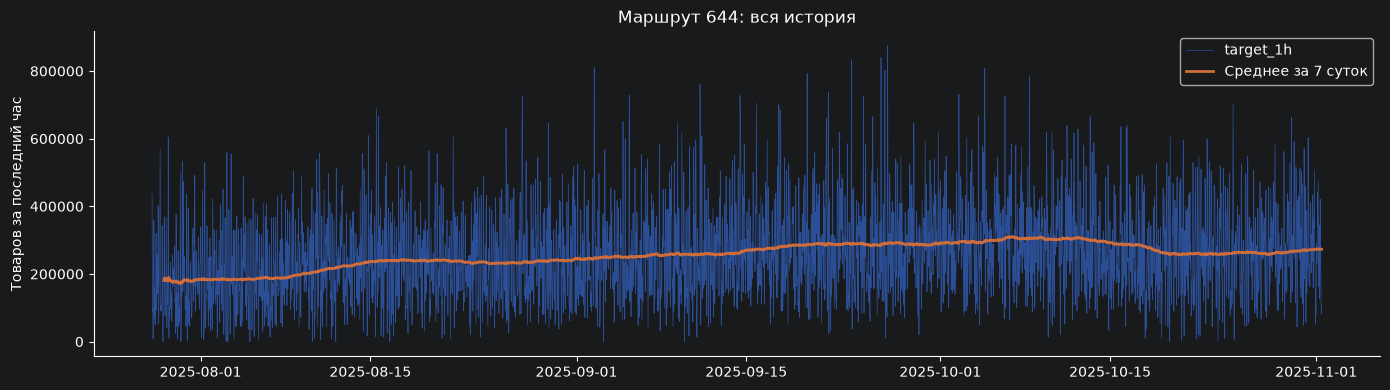

In [25]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y.index, y, lw=.5, alpha=.65, label=TARGET)
ax.plot(y.rolling(336, min_periods=48).mean(), lw=2, label="Среднее за 7 суток")
ax.set(title=f"Маршрут {ROUTE_ID}: вся история", ylabel="Товаров за последний час")
ax.legend()
plain_axes(fig)
fig.tight_layout()
plt.show()
plt.close(fig)

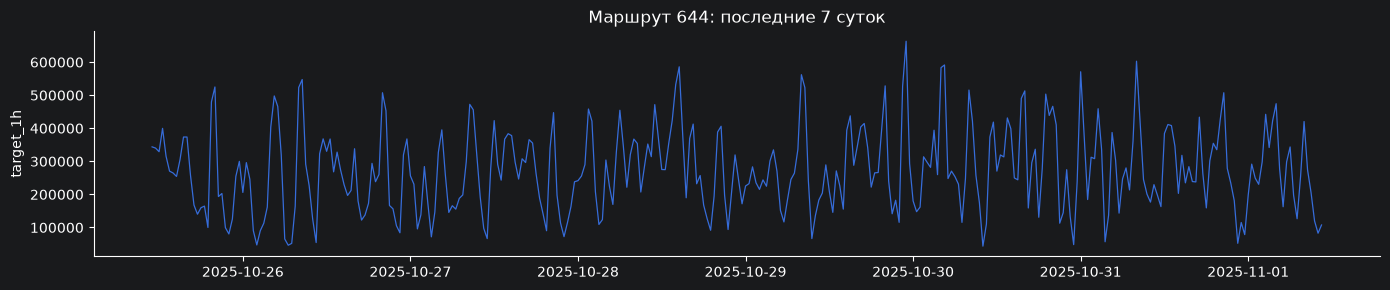

In [26]:
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(y.iloc[-336:], lw=.9)
ax.set(title=f"Маршрут {ROUTE_ID}: последние 7 суток", ylabel=TARGET)
plain_axes(fig)
fig.tight_layout()
plt.show()
plt.close(fig)

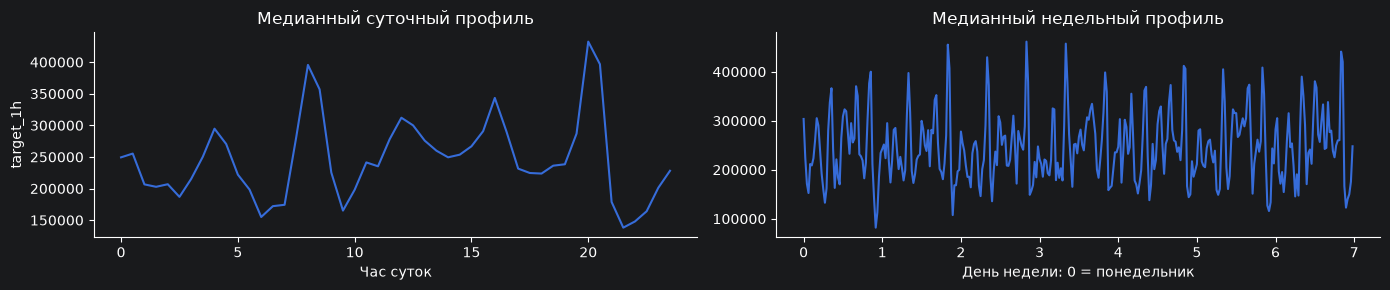

In [27]:
day_slot = y.index.hour * 2 + y.index.minute // 30
week_slot = y.index.day_of_week * 48 + day_slot
day_profile = y.groupby(day_slot).median().reindex(range(48))
week_profile = y.groupby(week_slot).median().reindex(range(336))

fig, axes = plt.subplots(1, 2, figsize=(14, 3))
axes[0].plot(np.arange(48) / 2, day_profile)
axes[0].set(title="Медианный суточный профиль", xlabel="Час суток", ylabel=TARGET)
axes[1].plot(np.arange(336) / 48, week_profile)
axes[1].set(title="Медианный недельный профиль", xlabel="День недели: 0 = понедельник")
plain_axes(fig)
fig.tight_layout()
plt.show()
plt.close(fig)

### 4.2. ACF — связь с прошлыми значениями

Шаг лага — 30 минут: 48 лагов = сутки, 336 = неделя. Полоса показывает номинальный
95% интервал около нуля. Часовое окно таргета перекрывается с соседним, поэтому
краткосрочная корреляция частично может объясняться этим перекрытием.

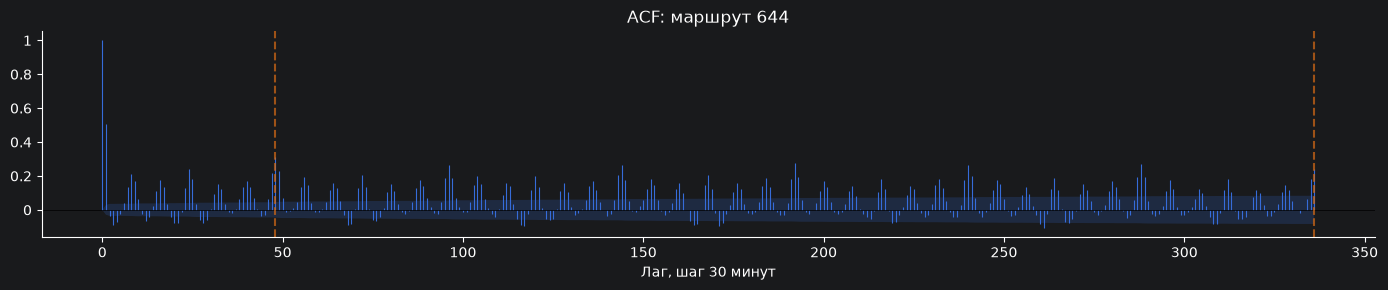

1       0.50686989
2     -0.034888742
48      0.30928059
336     0.24012829
Name: ACF, dtype: float64

In [28]:
acf_values, acf_intervals = acf(values, nlags=336, fft=True, alpha=.05, result_object=False)
lags = np.arange(len(acf_values))
fig, ax = plt.subplots(figsize=(14, 3))
ax.vlines(lags, 0, acf_values, lw=.8)
ax.fill_between(lags, acf_intervals[:, 0] - acf_values,
                acf_intervals[:, 1] - acf_values, alpha=.2)
ax.axhline(0, color="black", lw=.5)
for lag in [48, 336]:
    ax.axvline(lag, color="#d76b15", ls="--", alpha=.7)
ax.set(title=f"ACF: маршрут {ROUTE_ID}", xlabel="Лаг, шаг 30 минут")
plain_axes(fig)
fig.tight_layout()
plt.show()
plt.close(fig)
display(pd.Series({lag: acf_values[lag] for lag in [1, 2, 48, 336]}, name="ACF"))

### 4.3. PACF — частичная автокорреляция

PACF оценивает дополнительную линейную связь на лаге после учёта промежуточных
лагов. Здесь рассматриваем 96 лагов, то есть двое суток.

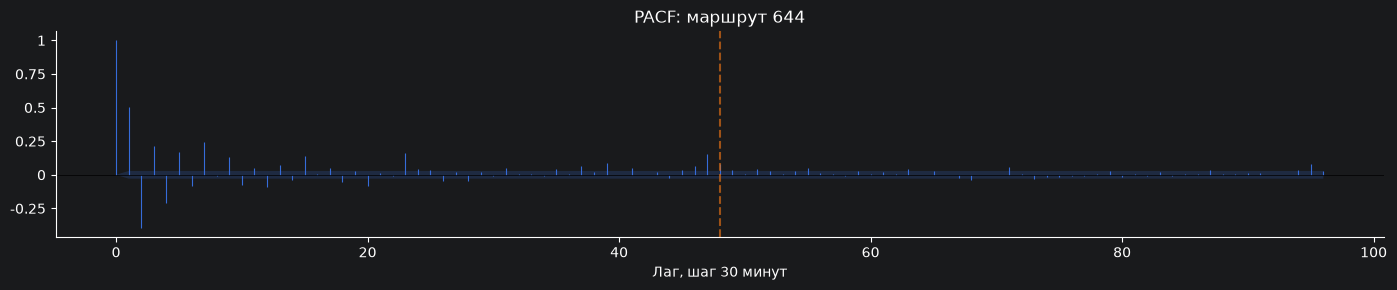

In [29]:
pacf_values, pacf_intervals = pacf(values, nlags=96, method="ywm", alpha=.05)
lags = np.arange(len(pacf_values))
fig, ax = plt.subplots(figsize=(14, 3))
ax.vlines(lags, 0, pacf_values, lw=.8)
ax.fill_between(lags, pacf_intervals[:, 0] - pacf_values,
                pacf_intervals[:, 1] - pacf_values, alpha=.2)
ax.axhline(0, color="black", lw=.5)
ax.axvline(48, color="#d76b15", ls="--", alpha=.7)
ax.set(title=f"PACF: маршрут {ROUTE_ID}", xlabel="Лаг, шаг 30 минут")
plain_axes(fig)
fig.tight_layout()
plt.show()
plt.close(fig)

### 4.4. ADF и KPSS

У ADF нулевая гипотеза — единичный корень; у KPSS — стационарность около уровня
(`c`) или линейного тренда (`ct`). Низкое p-value в этих тестах имеет разный смысл.
При противоречии не назначаем дифференцирование автоматически. Предупреждения
о границе табличных p-value показываем вместе с результатами.

In [30]:
test_results = stationarity_tests(values)
test_rows = []
for name in ["adf", "kpss"]:
    for regression in ["c", "ct"]:
        prefix = f"{name}_{regression}"
        test_rows.append({"test": name.upper(), "regression": regression,
                          "statistic": test_results.get(prefix + "_stat"),
                          "pvalue": test_results.get(prefix + "_pvalue"),
                          "lags": test_results.get(prefix + "_lags"),
                          "warning": test_results.get(prefix + "_warning", ""),
                          "status": test_results.get(prefix + "_status", "")})
test_table = pd.DataFrame(test_rows)
display(test_table)

,test,regression,statistic,pvalue,lags,warning,status
0,ADF,c,-4.3163738,0.00041608752,48,adfuller currently returns a plain tuple whose...,ok
1,ADF,ct,-5.7080038,0.0000088220218,48,adfuller currently returns a plain tuple whose...,ok
2,KPSS,c,20.271316,0.01,0,The test statistic is outside of the range of ...,ok
3,KPSS,ct,1.2824225,0.01,23,The test statistic is outside of the range of ...,ok


### 4.5. Анализ Фурье

Перед спектральной оценкой удаляется линейный тренд и применяется окно Hann.
Сильный пик показывает повторение на соответствующем периоде, но длинная волна
с одним-двумя циклами ещё не подтверждает устойчивую сезонность.

In [31]:
frequencies, power, peaks = fourier_analysis(values)
fourier_table = pd.DataFrame([
    {"period_hours": 1 / frequencies[index],
     "cycles_in_history": len(y) * .5 * frequencies[index],
     "power_share": power[index] / power.sum()}
    for index in peaks[:10]
])
display(fourier_table)

,period_hours,cycles_in_history,power_share
0,3.9982729,579,0.050608005
1,24.114583,96,0.018193649
2,6.012987,385,0.011671672
3,2315,1,0.0083529981
4,2.4014523,964,0.0078217187
5,2.9987047,772,0.0075345917
6,2.0008643,1157,0.0060579564
7,4.033101,574,0.004685824
8,3.7888707,611,0.004052713
9,11.994819,193,0.0040051108


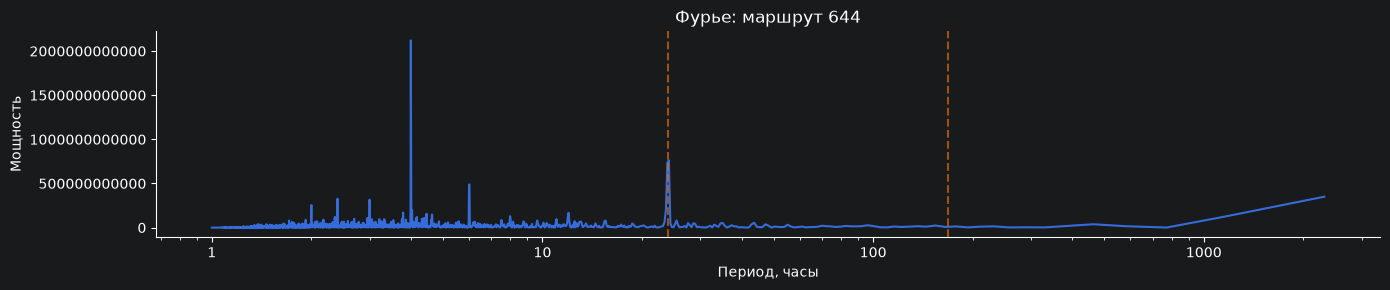

In [32]:
nonzero = frequencies > 0
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(1 / frequencies[nonzero], power[nonzero])
ax.set(xscale="log", title=f"Фурье: маршрут {ROUTE_ID}", xlabel="Период, часы", ylabel="Мощность")
for period in [24, 168]:
    ax.axvline(period, color="#d76b15", ls="--", alpha=.7)
plain_axes(fig)
fig.tight_layout()
plt.show()
plt.close(fig)

### 4.6. Перебор параметров STL

`period` — длина цикла в получасовых точках, `seasonal` — нечётное окно сезонного
сглаживания. Проверяем сутки, неделю и до трёх спектральных периодов. Спектральные
кандидаты выбираются **до первого проверочного окна**, минимум по пяти циклам.

Для **этого одного маршрута** перебираем `seasonal = 7, 13, 25, 51`, `robust=True`.
Проверка — три последние недели: прогноз повторяет последнюю сезонную компоненту
и продолжает тренд линейно по последним 48 точкам. Выбор по средней MAE; в пределах
1% от лучшей ошибки предпочитаем большее `seasonal`, затем меньший `period`.
Расчёт перебора вынесен в `stl_search` в отдельном файле.

In [33]:
candidate_periods, validation_origins = stl_candidates(raw)
print("Периоды, шаги по 30 минут:", candidate_periods)
print("Периоды, часы:", [period / 2 for period in candidate_periods])
print("Границы проверок:", [str(raw.index[cut - 1]) for cut in validation_origins])

Периоды, шаги по 30 минут: [48, 336, 8, 12, 5]
Периоды, часы: [24.0, 168.0, 4.0, 6.0, 2.5]
Границы проверок: ['2025-10-11 10:30:00', '2025-10-18 10:30:00', '2025-10-25 10:30:00']


In [34]:
stl_results, stl_trials, stl_components = stl_search(raw)
if stl_results["stl_status"] != "ok":
    raise ValueError(stl_results["stl_status"])

stl_scores = stl_trials.groupby(["period", "seasonal"]).mae.agg(["mean", "min", "max"])
display(stl_scores.sort_values("mean"))
print("Выбранный period:", stl_results["stl_period"])
print("Выбранный seasonal:", stl_results["stl_seasonal"])
print("Совпадение выбора между окнами:", f"{stl_results['stl_selection_agreement']:.0%}")

mean       min       max
period seasonal                              
336    51       111269.83 100875.72 119190.11
       25        111883.6 101713.47 119964.21
       13       114435.02 103316.22 123703.27
       7        120463.91 109581.08 126670.69
48     13       134845.26 97612.327 181836.83
       25       135084.25 132083.38 139427.29
5      25       140657.79 108597.36 199986.75
48     51       141750.72 100507.22 163753.87
12     25       160072.97 122136.06 229012.29
48     7        163852.58 114291.79  219024.1
12     13        168851.4 119590.22 235070.25
       51       169351.56 124310.47 236343.08
5      13       172624.21 140469.81 215199.63
       51       174414.37 117234.89  204593.3
12     7        184533.72  144534.9 257587.36
8      51       186467.02 113080.24 230223.24
       25       188253.21  111234.5 229548.96
       13       202813.77 126978.39 243661.28
       7        208082.96 147974.79 242246.79
5      7         209863.1 180898.78 231964.76

Выбранный period: 336
Выбранный seasonal: 51
Совпадение выбора между окнами: 0%


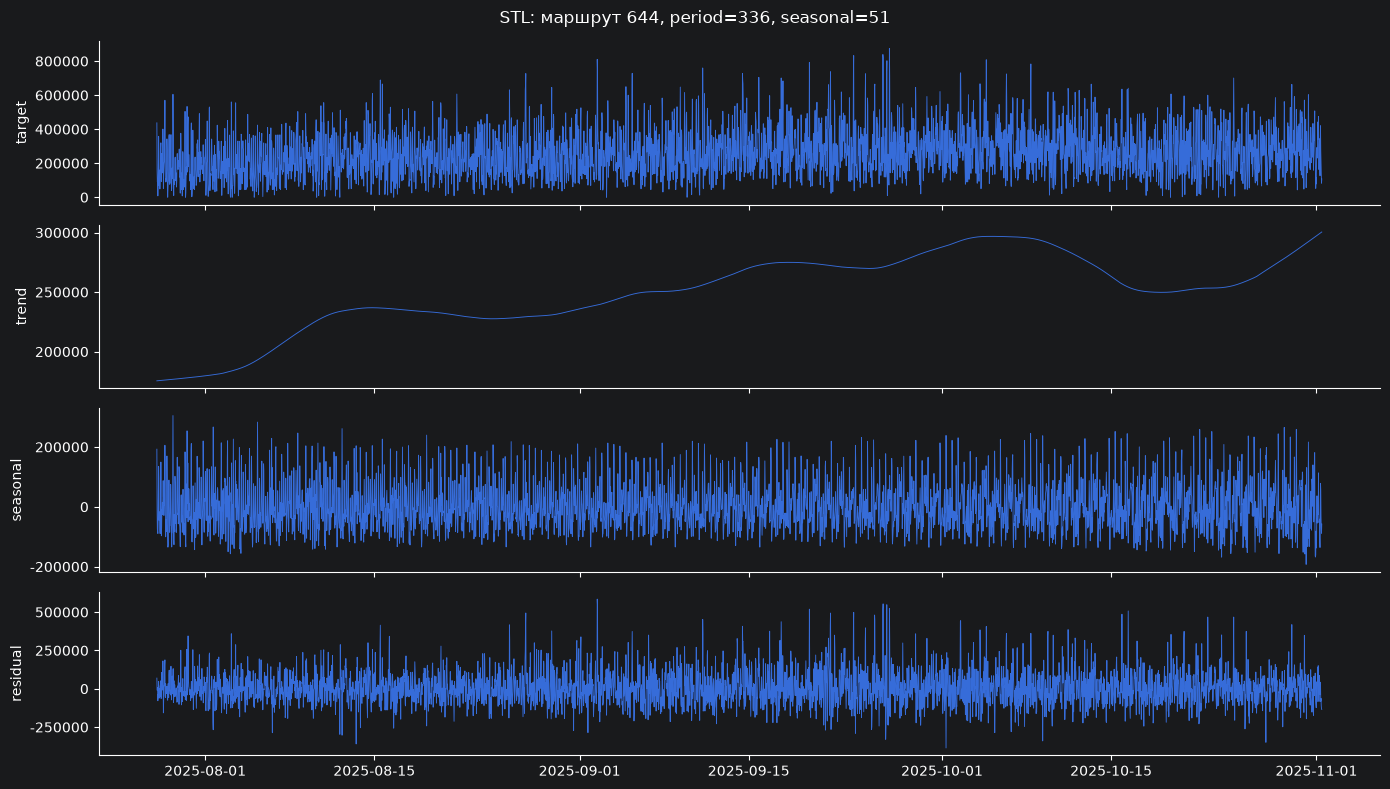

In [35]:
decomposition = pd.DataFrame({
    "target": values,
    "trend": stl_components["best_trend"],
    "seasonal": stl_components["best_seasonal"],
    "residual": stl_components["best_resid"],
}, index=y.index)

fig, axes = plt.subplots(4, 1, figsize=(14, 8), sharex=True)
for ax, column in zip(axes, decomposition.columns):
    ax.plot(decomposition.index, decomposition[column], lw=.65)
    ax.set_ylabel(column)
fig.suptitle(f"STL: маршрут {ROUTE_ID}, period={stl_results['stl_period']}, "
             f"seasonal={stl_results['stl_seasonal']}")
plain_axes(fig)
fig.tight_layout()
plt.show()
plt.close(fig)

In [36]:
display(pd.Series({
    "Сила тренда": stl_results["stl_best_trend_strength"],
    "Сила сезонности": stl_results["stl_best_season_strength"],
    "ACF остатка на лаге 1": stl_results["stl_best_resid_acf1"],
    "Автоматическое окно тренда": stl_results["stl_best_trend_window"],
    "Средняя MAE проверки": stl_results["stl_cv_mae"],
}, name=f"Маршрут {ROUTE_ID}"))

Сила тренда                  0.088835936
Сила сезонности               0.29804816
ACF остатка на лаге 1         0.41726117
Автоматическое окно тренда           521
Средняя MAE проверки           111269.83
Name: Маршрут 644, dtype: float64

### 4.7. Тренд и устойчивость сезонного профиля

Дополнительно описываем форму медленного изменения при фиксированной настройке
`period=336, seasonal=51` (окно тренда около 11 дней). Это позволяет отделить
форму тренда от выбора самого короткого STL-периода.

Для сезонного профиля после удаления этого тренда проверяем периоды
2, 3, 4, 6, 8, 12, 24 часа и неделю. Нужны выигрыш MSE минимум 1%, корреляция
профилей разных частей истории ≥0.5 и улучшение хотя бы в 2/3 недельных окон.
Тренд оценён по всей истории: это диагностика повторяемости, не оценка будущего
качества модели без утечки. Полные критерии реализованы в отдельном файле.

In [37]:
if stl_results.get("stl_week_seasonal") == 51:
    common_trend = stl_components["week_trend"]
else:
    common_trend = STL(values, period=336, seasonal=51, robust=True).fit().trend

trend_features, weekly_levels, weekly_centers = trend_shape(values, common_trend)
trend_group = trend_label(trend_features)
print("Форма тренда:", trend_group)
display(pd.Series({
    "Размах тренда / средний объём": trend_features["trend_span_over_mean"],
    "Изменение конца относительно начала": trend_features["trend_end_start_change"],
    "Корреляция уровня со временем": trend_features["trend_time_correlation"],
    "Изменение последних двух недель / средний объём": trend_features["recent_trend_change"],
}))

Форма тренда: Преимущественно рост


Размах тренда / средний объём                      0.28918635
Изменение конца относительно начала                0.56846706
Корреляция уровня со временем                      0.78461538
Изменение последних двух недель / средний объём   0.088825583
dtype: float64

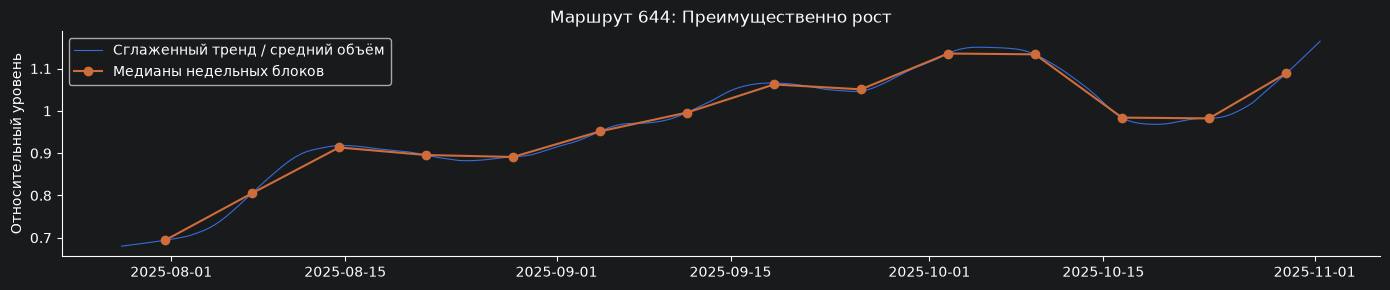

In [38]:
fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(y.index, common_trend / values.mean(), lw=.8, label="Сглаженный тренд / средний объём")
ax.plot(y.index[np.round(weekly_centers).astype(int)], weekly_levels, "o-", label="Медианы недельных блоков")
ax.set(title=f"Маршрут {ROUTE_ID}: {trend_group}", ylabel="Относительный уровень")
ax.legend()
plain_axes(fig)
fig.tight_layout()
plt.show()
plt.close(fig)

In [39]:
season_features = seasonal_features(values, common_trend)
season_group = season_label(season_features)
period_table = pd.DataFrame([
    {"period_hours": period / 2,
     "gain": season_features[f"period_{period}_gain"],
     "profile_correlation": season_features[f"period_{period}_correlation"],
     "positive_windows": season_features[f"period_{period}_positive_windows"]}
    for period in [4, 6, 8, 12, 16, 24, 48, 336]
])
display(period_table)
print("Повторяемый профиль:", season_group["season_group"])
print("Поддержанные периоды, получасовые шаги:", season_group["supported_periods_steps"])
print("Дополнительный недельный эффект:", season_group["weekly_extra_supported"])

,period_hours,gain,profile_correlation,positive_windows
0,2,0.0064051052,0.9927713,0.77777778
1,3,0.02279053,0.95721568,0.77777778
2,4,0.082315708,0.98135344,0.88888889
3,6,0.039645972,0.82515726,0.88888889
4,8,0.082459455,0.94089574,0.88888889
5,12,0.12896932,0.91440723,0.88888889
6,24,0.15678946,0.87207143,1
7,168,0.088860934,-0.07156109,0.77777778


Повторяемый профиль: Профиль 24 ч
Поддержанные периоды, получасовые шаги: 6;8;12;16;24;48
Дополнительный недельный эффект: False


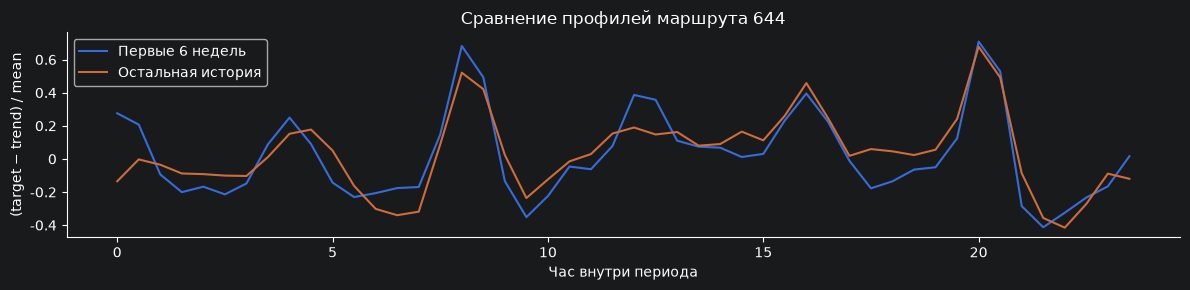

In [40]:
profile_period = season_group["profile_period_steps"] or 48
clean = (values - common_trend) / values.mean()
phase = np.arange(len(clean)) % profile_period
split = 6 * 336
first_profile = profile_mean(clean[:split], phase[:split], profile_period)
second_profile = profile_mean(clean[split:], phase[split:], profile_period)

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(np.arange(profile_period) / 2, first_profile, label="Первые 6 недель")
ax.plot(np.arange(profile_period) / 2, second_profile, label="Остальная история")
ax.set(title=f"Сравнение профилей маршрута {ROUTE_ID}", xlabel="Час внутри периода",
       ylabel="(target − trend) / mean")
ax.legend()
plain_axes(fig)
fig.tight_layout()
plt.show()
plt.close(fig)

### 4.8. Вейвлет-анализ

В отличие от общего спектра Фурье, карта Morlet показывает, как менялась мощность
разных периодов во времени. Проверяем от 2 часов до 14 суток. Краевые области
закрашены: там оценка менее надёжна. Мощность делим на масштаб перед сравнением.

In [41]:
wavelet_results, wavelet_arrays = wavelet_analysis(values)
wavelet_periods = wavelet_arrays["wavelet_periods_h"]
wavelet_power = wavelet_arrays["wavelet_power"]
wavelet_edges = wavelet_arrays["wavelet_edge_steps"].astype(int)
display(pd.Series(wavelet_results, name=f"Маршрут {ROUTE_ID}"))

wavelet_period_h             3.833619
wavelet_period_median_h     3.5341631
wavelet_log_period_std     0.66483479
wavelet_valid_time_share   0.99784017
Name: Маршрут 644, dtype: float64

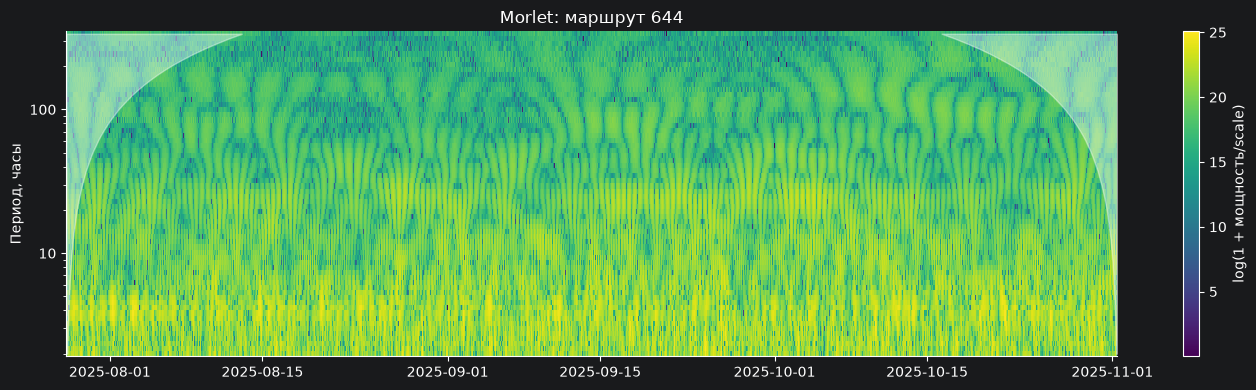

In [42]:
fig, ax = plt.subplots(figsize=(14, 4))
im = ax.pcolormesh(y.index, wavelet_periods, np.log1p(wavelet_power), shading="auto", cmap="viridis")
left = np.minimum(wavelet_edges, len(y) - 1)
right = np.maximum(0, len(y) - 1 - wavelet_edges)
ax.fill_betweenx(wavelet_periods, y.index[0], y.index[left], color="white", alpha=.4)
ax.fill_betweenx(wavelet_periods, y.index[right], y.index[-1], color="white", alpha=.4)
ax.set(yscale="log", title=f"Morlet: маршрут {ROUTE_ID}", ylabel="Период, часы")
fig.colorbar(im, ax=ax, label="log(1 + мощность/scale)")
plain_axes(fig)
fig.tight_layout()
plt.show()
plt.close(fig)

### 4.9. Первая разность как кандидат

Сравним ряд с `diff(1)`, то есть изменением относительно предыдущих 30 минут.
Повторно посмотрим тесты и ACF. Наличие тренда само по себе не назначает порядок
разности: подходящий вариант затем сравнивают по качеству прогноза на временных срезах.

In [43]:
difference = y.diff().dropna()
difference_tests = stationarity_tests(difference.to_numpy())
difference_comparison = pd.DataFrame([
    {"series": label, "adf_c_pvalue": result.get("adf_c_pvalue"),
     "kpss_c_pvalue": result.get("kpss_c_pvalue"),
     "adf_ct_pvalue": result.get("adf_ct_pvalue"),
     "kpss_ct_pvalue": result.get("kpss_ct_pvalue")}
    for label, result in [("Исходный ряд", test_results), ("Первая разность", difference_tests)]
])
display(difference_comparison)
display(pd.Series({key: value for key, value in difference_tests.items()
                   if key.endswith("_warning")}, name="Предупреждения тестов разности"))

,series,adf_c_pvalue,kpss_c_pvalue,adf_ct_pvalue,kpss_ct_pvalue
0,Исходный ряд,0.00041608752,0.01,0.0000088220218,0.01
1,Первая разность,0,0.1,0,0.1


adf_c_warning      adfuller currently returns a plain tuple whose...
kpss_c_warning     The test statistic is outside of the range of ...
adf_ct_warning     adfuller currently returns a plain tuple whose...
kpss_ct_warning    The test statistic is outside of the range of ...
Name: Предупреждения тестов разности, dtype: str

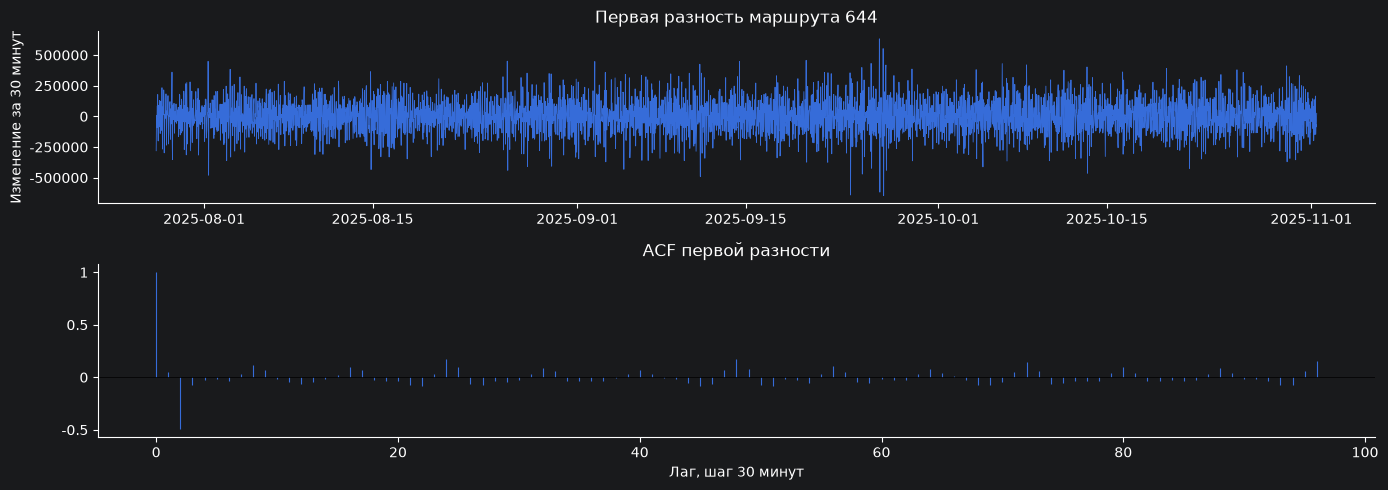

In [44]:
difference_acf = acf(difference, nlags=96, fft=True, result_object=False)
fig, axes = plt.subplots(2, 1, figsize=(14, 5))
axes[0].plot(difference, lw=.6)
axes[0].set(title=f"Первая разность маршрута {ROUTE_ID}", ylabel="Изменение за 30 минут")
axes[1].vlines(np.arange(len(difference_acf)), 0, difference_acf, lw=.8)
axes[1].axhline(0, color="black", lw=.5)
axes[1].set(title="ACF первой разности", xlabel="Лаг, шаг 30 минут")
plain_axes(fig)
fig.tight_layout()
plt.show()
plt.close(fig)

## 5. Вывод по выбранному маршруту

Выводы ниже относятся только к `ROUTE_ID`. Они не заменяют результаты по другим
маршрутам. При смене идентификатора все значения и графики пересчитываются.

**Маршрут 644.** История 2025-07-28 00:00:00 — 2025-11-01 10:30:00.

- Форма медленного тренда: **Преимущественно рост**.
- Поддержанный сезонный профиль: **Профиль 24 ч**.
- Дополнительный недельный эффект: **False**.
- Выбор STL: `period=336`, `seasonal=51`;
  совпадение выбора между окнами **0%**.
- ACF на суточном лаге: **0.309**, на недельном: **0.240**.
- Первая разность рассмотрена как кандидат; порядок дифференцирования автоматически не назначается.

In [45]:
EXAMPLE_OUT = OUT / f"route_{ROUTE_ID}"
EXAMPLE_OUT.mkdir(exist_ok=True)
for name, table in {"stationarity": test_table, "fourier": fourier_table,
                    "stl_trials": stl_trials, "seasonal_profiles": period_table,
                    "difference_comparison": difference_comparison}.items():
    table.to_csv(EXAMPLE_OUT / f"{name}.csv", index=False, float_format=lambda x: np.format_float_positional(x, trim="-"))
decomposition.to_csv(EXAMPLE_OUT / "decomposition.csv", index_label="timestamp", float_format=lambda x: np.format_float_positional(x, trim="-"))
print("Сохранено:", EXAMPLE_OUT)

Сохранено: /Users/sptrent/projects/rwb_case/artifacts/eda/route_644


## 6. Feature engineering

Определения и доступность признаков — в [docs/feature_engineering.md](docs/feature_engineering.md),
реализация — в [feature_engineering.py](feature_engineering.py).
Ниже используем размеченную history и исходный submission и маршрут `ROUTE_ID` из раздела 4.

**1198 модельных признаков:** 16 календарных, 660 лагов и 352 дополнительных признака соседних слотов, 28 разностей,
140 скользящих статистик, категориальный route_id и horizon.
id, cutoff, timestamp и метка y в модельные признаки не входят.

In [ ]:
import json
import feature_engineering as fe
from rwb_research.core import make_requests, write_features, read_features

FEATURE_OUT = ROOT / "artifacts/features"
FEATURE_OUT.mkdir(parents=True, exist_ok=True)
fe.validate_history(history)

### 6.1. Данные и доступная история

cutoff — общий момент начала прогноза. Все восемь моделей используют историю до cutoff
включительно. timestamp = cutoff + horizon × 30 минут — время целевой точки.
Календарь рассчитывается по cutoff и timestamp. Слот прошлых дней выбирается по timestamp. Граница доступной истории — cutoff.
Будущие факты не используются, даже если присутствуют в переданной history.

In [ ]:
dictionary = fe.feature_dictionary()
model_features = fe.FEATURE_NAMES
if not (len(model_features) == len(set(model_features)) == 1198):
    raise ValueError('Нарушено условие: len(model_features) == len(set(model_features)) == 1198')
display(dictionary.groupby("family").size().rename("features").to_frame())
display(dictionary.head(18))

,features
family,
calendar,16
difference,28
forecast_slot,352
horizon,1
lag,660
rolling,140
route,1


,feature,family,formula
0,route_id,route,Категория маршрута
1,horizon,horizon,Число будущих получасовых шагов: 1–8
2,day_of_month_sin,calendar,sin(2π×(day−1)/days_in_month); время прогнозир...
3,day_of_month_cos,calendar,cos(2π×(day−1)/days_in_month); время прогнозир...
4,day_of_week_sin,calendar,sin(2π×weekday/7); время прогнозируемой точки
5,day_of_week_cos,calendar,cos(2π×weekday/7); время прогнозируемой точки
6,hour_sin,calendar,sin(2π×hour/24); время прогнозируемой точки
7,hour_cos,calendar,cos(2π×hour/24); время прогнозируемой точки
8,half_hour_sin,calendar,sin(2π×(hour×2+minute//30)/48); время прогнози...
9,half_hour_cos,calendar,cos(2π×(hour×2+minute//30)/48); время прогнози...


### 6.2. Пример одного маршрута

При cutoff = 10:30 сразу прогнозируем 11:00, 11:30, …, 14:30.
Все восемь строк имеют одинаковые лаги, разности и скользящие статистики.
Календарь cutoff общий для всех восьми строк. С горизонтом меняются календарь прогнозируемой точки и значения статусов для того же слота прошлых дней.

Сохраняем нумерацию от первой будущей точки: lag_1 = x(cutoff),
lag_2 = x(cutoff − 30 минут), lag_336 = x(cutoff − 335 × 30 минут).
То есть lag_1 в этом наборе — последний известный факт, а не сдвиг от каждой будущей цели.
Разность diff_336 сравнивает факт в cutoff со значением ровно неделю назад.
Прогноз одной модели не передаётся другим моделям.

In [ ]:
cutoff = history.loc[history.route_id.eq(ROUTE_ID), "timestamp"].max()
example_requests = make_requests([ROUTE_ID], [cutoff])
example = fe.build_features(history.loc[history.route_id.eq(ROUTE_ID)], example_requests)
display(example[["route_id", "cutoff", "timestamp", "horizon",
                 "target_lag_1", "target_lag_2", "target_lag_48", "target_lag_336"]])

,route_id,cutoff,timestamp,horizon,target_lag_1,target_lag_2,target_lag_48,target_lag_336
0,644,2025-11-01 10:30:00,2025-11-01 11:00:00,1,107514,82631,197188,343811
1,644,2025-11-01 10:30:00,2025-11-01 11:30:00,2,107514,82631,197188,343811
2,644,2025-11-01 10:30:00,2025-11-01 12:00:00,3,107514,82631,197188,343811
3,644,2025-11-01 10:30:00,2025-11-01 12:30:00,4,107514,82631,197188,343811
4,644,2025-11-01 10:30:00,2025-11-01 13:00:00,5,107514,82631,197188,343811
5,644,2025-11-01 10:30:00,2025-11-01 13:30:00,6,107514,82631,197188,343811
6,644,2025-11-01 10:30:00,2025-11-01 14:00:00,7,107514,82631,197188,343811
7,644,2025-11-01 10:30:00,2025-11-01 14:30:00,8,107514,82631,197188,343811


### 6.3. Календарь через sin/cos

Месяц и день года исключены: история короче года.
день месяца: (day−1)/число дней в месяце; день недели: weekday/7;
час: hour/24; получасовой слот: (hour×2+minute//30)/48.
Для каждой фазы считаем sin(2π×phase) и cos(2π×phase) дважды. Колонки с префиксом `cutoff_` относятся к началу прогноза, остальные календарные колонки — к прогнозируемой точке.

Получасовые слоты — **0–47**. Час и слот частично дублируют информацию;
оба признака оставлены по запросу. Сырые календарные числа не входят в модельный набор.

In [ ]:
calendar_columns = dictionary.loc[dictionary.family.eq("calendar"), "feature"].tolist()
display(example[["cutoff", "timestamp", *calendar_columns]])

,cutoff,timestamp,day_of_month_sin,day_of_month_cos,day_of_week_sin,day_of_week_cos,hour_sin,hour_cos,half_hour_sin,half_hour_cos,cutoff_day_of_month_sin,cutoff_day_of_month_cos,cutoff_day_of_week_sin,cutoff_day_of_week_cos,cutoff_hour_sin,cutoff_hour_cos,cutoff_half_hour_sin,cutoff_half_hour_cos
0,2025-11-01 10:30:00,2025-11-01 11:00:00,0,1,-0.97492791,-0.22252093,0.25881905,-0.96592583,0.25881905,-0.96592583,0,1,-0.97492791,-0.22252093,0.5,-0.8660254,0.38268343,-0.92387953
1,2025-11-01 10:30:00,2025-11-01 11:30:00,0,1,-0.97492791,-0.22252093,0.25881905,-0.96592583,0.13052619,-0.99144486,0,1,-0.97492791,-0.22252093,0.5,-0.8660254,0.38268343,-0.92387953
2,2025-11-01 10:30:00,2025-11-01 12:00:00,0,1,-0.97492791,-0.22252093,0,-1,0,-1,0,1,-0.97492791,-0.22252093,0.5,-0.8660254,0.38268343,-0.92387953
3,2025-11-01 10:30:00,2025-11-01 12:30:00,0,1,-0.97492791,-0.22252093,0,-1,-0.13052619,-0.99144486,0,1,-0.97492791,-0.22252093,0.5,-0.8660254,0.38268343,-0.92387953
4,2025-11-01 10:30:00,2025-11-01 13:00:00,0,1,-0.97492791,-0.22252093,-0.25881905,-0.96592583,-0.25881905,-0.96592583,0,1,-0.97492791,-0.22252093,0.5,-0.8660254,0.38268343,-0.92387953
5,2025-11-01 10:30:00,2025-11-01 13:30:00,0,1,-0.97492791,-0.22252093,-0.25881905,-0.96592583,-0.38268343,-0.92387953,0,1,-0.97492791,-0.22252093,0.5,-0.8660254,0.38268343,-0.92387953
6,2025-11-01 10:30:00,2025-11-01 14:00:00,0,1,-0.97492791,-0.22252093,-0.5,-0.8660254,-0.5,-0.8660254,0,1,-0.97492791,-0.22252093,0.5,-0.8660254,0.38268343,-0.92387953
7,2025-11-01 10:30:00,2025-11-01 14:30:00,0,1,-0.97492791,-0.22252093,-0.5,-0.8660254,-0.60876143,-0.79335334,0,1,-0.97492791,-0.22252093,0.5,-0.8660254,0.38268343,-0.92387953


### 6.4. Лаги таргета и шести статусов

Таргет: лаги 1–336. Каждый статус: 1–48 и 96, 144, 192, 240, 288, 336.
Формула для всех горизонтов: lag_k = x(cutoff − (k−1) × 30 минут).
Расчёт отдельно по маршруту на получасовой сетке. Реальные пропуски остаются NaN.

Для каждого показателя берём девять получасовых точек вокруг будущего слота за каждые из последних семи суток. Смещения от −4 до +4 соответствуют ±2 часам. Совпадающие обычные лаги повторно в модель не включаются. Например, _slot_7d_m4 — на два часа раньше будущего слота неделю назад.

In [ ]:
lag_columns = [name for name in model_features if "_lag_" in name]
print("Лаговых признаков:", len(lag_columns))
display(example.loc[:, [f"{column}_lag_{lag}" for column in ["target", *fe.STATUSES]
                        for lag in [1, 2, 48, 336]]].head(1).T)
display(example[["cutoff", "timestamp", "horizon", "status_1_lag_336", "status_1_slot_7d_m4", "status_1_slot_7d", "status_1_slot_7d_p4"]])

,0
target_lag_1,107514
target_lag_2,82631
target_lag_48,197188
target_lag_336,343811
status_1_lag_1,22
status_1_lag_2,19
status_1_lag_48,26
status_1_lag_336,15
status_2_lag_1,15
status_2_lag_2,26


,cutoff,timestamp,horizon,status_1_lag_336,status_1_slot_7d_m4,status_1_slot_7d,status_1_slot_7d_p4
0,2025-11-01 10:30:00,2025-11-01 11:00:00,1,15,33,15,25
1,2025-11-01 10:30:00,2025-11-01 11:30:00,2,15,15,13,23
2,2025-11-01 10:30:00,2025-11-01 12:00:00,3,15,31,11,11
3,2025-11-01 10:30:00,2025-11-01 12:30:00,4,15,26,18,18
4,2025-11-01 10:30:00,2025-11-01 13:00:00,5,15,15,25,24
5,2025-11-01 10:30:00,2025-11-01 13:30:00,6,15,13,23,25
6,2025-11-01 10:30:00,2025-11-01 14:00:00,7,15,11,11,23
7,2025-11-01 10:30:00,2025-11-01 14:30:00,8,15,18,18,11


Лаговых признаков: 660


### 6.5. Разности

Для всех горизонтов diff_k = x(cutoff) − x(cutoff − k × 30 минут).
При k = 1, 2, 48, 336 получаем изменение за полчаса, час, сутки и неделю.
Все значения известны в момент начала прогноза.

In [ ]:
difference_columns = [name for name in model_features if "_diff_" in name]
print("Разностных признаков:", len(difference_columns))
display(example[difference_columns].head(1).T)

,0
target_diff_1,24883
target_diff_2,-12348
target_diff_48,-121975
target_diff_336,-44227
status_1_diff_1,3
status_1_diff_2,-6
status_1_diff_48,-17
status_1_diff_336,-4
status_2_diff_1,-11
status_2_diff_2,-19


Разностных признаков: 28


### 6.6. Скользящие статистики

Для семи показателей: mean, median, std, min и max.
Окна 6, 12, 48, 336 точек соответствуют 3 часам, 6 часам, суткам и неделе.
Окно заканчивается в cutoff включительно для всех восьми горизонтов; std использует ddof=0.
При cutoff = 10:30 трёхчасовое окно содержит точки 08:00–10:30.
Неполные окна остаются NaN. Часовые окна target_1h перекрываются: суммы этих значений
не равны количеству уникальных отгрузок.

In [ ]:
rolling_columns = [name for name in model_features if "_rolling_" in name]
print("Скользящих признаков:", len(rolling_columns))
display(example[[f"target_rolling_{operation}_{window}" for window in fe.WINDOWS
                 for operation in fe.OPERATIONS]].head(1).T)

,0
target_rolling_mean_6,201640.16666667
target_rolling_median_6,162609.5
target_rolling_std_6,117509.42116758
target_rolling_min_6,82631
target_rolling_max_6,420480
target_rolling_mean_12,216061.58333333
target_rolling_median_12,201319.5
target_rolling_std_12,99937.18199571
target_rolling_min_12,82631
target_rolling_max_12,420480


Скользящих признаков: 140


In [ ]:
route_history = history.loc[history.route_id.eq(ROUTE_ID)].set_index("timestamp").sort_index()
manual_rows = []
for window in fe.WINDOWS:
    past = route_history.loc[cutoff - (window - 1) * fe.STEP:cutoff, fe.TARGET]
    for operation in fe.OPERATIONS:
        expected = past.std(ddof=0) if operation == "std" else getattr(past, operation)()
        actual = example[f"target_rolling_{operation}_{window}"].iloc[0]
        if not (np.allclose(actual, expected, rtol=0.0000000001, atol=0, equal_nan=True)):
            raise ValueError("Результат проверки не совпал с ожидаемым")
        manual_rows.append({"window": window, "operation": operation, "feature": actual, "manual": expected})
display(pd.DataFrame(manual_rows))

,window,operation,feature,manual
0,6,mean,201640.16666667,201640.16666667
1,6,median,162609.5,162609.5
2,6,std,117509.42116758,117509.42116758
3,6,min,82631,82631
4,6,max,420480,420480
5,12,mean,216061.58333333,216061.58333333
6,12,median,201319.5,201319.5
7,12,std,99937.18199571,99937.18199571
8,12,min,82631,82631
9,12,max,420480,420480


### 6.7. Обучающая порция только из train

Пример берётся из последних двух дней train, метки ограничены train_end.
Ни одна обучающая метка не заходит в val. Здесь показан горизонт 1.
Исторические признаки всех горизонтов привязаны к общему cutoff,
а метки относятся к соответствующим будущим моментам времени.

In [ ]:
training_cutoff = train.timestamp.max()
training_example = next(fe.iter_training_features(
    train, start=training_cutoff - pd.Timedelta(days=2), route_ids=[ROUTE_ID],
    label_available_until=training_cutoff,
))
if not ("y" not in model_features):
    raise ValueError('Нарушено условие: "y" not in model_features')
if not (training_example.timestamp.le(training_cutoff).all()):
    raise ValueError('Нарушено условие: training_example.timestamp.le(training_cutoff).all()')
if not (not training_example[model_features].isna().any().any()):
    raise ValueError('Нарушено условие: not training_example[model_features].isna().any().any()')
display(training_example[["route_id", "cutoff", "timestamp", "horizon", "target_lag_1", "y"]].head(16))
print("Обучающий пример:", training_example.shape)

,route_id,cutoff,timestamp,horizon,target_lag_1,y
0,644,2025-09-29 13:30:00,2025-09-29 14:00:00,1,171553,234654
1,644,2025-09-29 14:00:00,2025-09-29 14:30:00,1,234654,327754
2,644,2025-09-29 14:30:00,2025-09-29 15:00:00,1,327754,323341
3,644,2025-09-29 15:00:00,2025-09-29 15:30:00,1,323341,365455
4,644,2025-09-29 15:30:00,2025-09-29 16:00:00,1,365455,340337
5,644,2025-09-29 16:00:00,2025-09-29 16:30:00,1,340337,333341
6,644,2025-09-29 16:30:00,2025-09-29 17:00:00,1,333341,232259
7,644,2025-09-29 17:00:00,2025-09-29 17:30:00,1,232259,404939
8,644,2025-09-29 17:30:00,2025-09-29 18:00:00,1,404939,592174
9,644,2025-09-29 18:00:00,2025-09-29 18:30:00,1,592174,426630


Обучающий пример: (96, 1201)


### 6.8. Пример признаков первого окна val

Полная val содержит последние 15% от первых 80% размеченной истории. Проверяем её последовательными
блоками до восьми получасовых точек; последний блок короче. Каждая строка val
оценивается ровно один раз. Здесь только первые четыре часа для всех маршрутов.
Все восемь прогнозов маршрута используют одну историю до конца train включительно.
Для следующих блоков доступны факты до нового cutoff. Внутри блока ответы не используются.

In [ ]:
val_requests = ds.validation_requests(val)
if not (len(val_requests) == len(val)):
    raise ValueError('Нарушено условие: len(val_requests) == len(val)')
if not (val_requests.cutoff.min() == train.timestamp.max()):
    raise ValueError('Нарушено условие: val_requests.cutoff.min() == train.timestamp.max()')
first_val_cutoff = val_requests.cutoff.min()
example_requests = val_requests.loc[val_requests.cutoff.eq(first_val_cutoff)]
validation_example = fe.build_features(history, example_requests)
source = val[["route_id", "timestamp", fe.TARGET]].rename(columns={fe.TARGET: "y"})
label_index = pd.MultiIndex.from_frame(validation_example[["route_id", "timestamp"]])
validation_example["y"] = source.set_index(["route_id", "timestamp"]).y.reindex(label_index).to_numpy()
if not (isinstance(validation_example.route_id.dtype, pd.CategoricalDtype)):
    raise ValueError('Нарушено условие: isinstance(validation_example.route_id.dtype, pd.CategoricalDtype)')
if not (len(validation_example) == 8000):
    raise ValueError('Нарушено условие: len(validation_example) == 8000')
if not (validation_example.y.notna().all()):
    raise ValueError('Нарушено условие: validation_example.y.notna().all()')
if not (not validation_example.loc[validation_example.horizon.eq(1), model_features].isna().any().any()):
    raise ValueError('Нарушено условие: not validation_example.loc[validation_example.horizon.eq(1), model_features].isna().any().any()')
if not (not validation_example[model_features].isna().any().any()):
    raise ValueError('Нарушено условие: not validation_example[model_features].isna().any().any()')
print("Полная val:", val.shape, "пример признаков:", validation_example.shape)
display(validation_example[["route_id", "cutoff", "timestamp", "horizon", "target_lag_1", "y"]].head(8))

,route_id,cutoff,timestamp,horizon,target_lag_1,y
0,471,2025-10-01 13:30:00,2025-10-01 14:00:00,1,81922,207142
1,471,2025-10-01 13:30:00,2025-10-01 14:30:00,2,81922,281022
2,471,2025-10-01 13:30:00,2025-10-01 15:00:00,3,81922,186662
3,471,2025-10-01 13:30:00,2025-10-01 15:30:00,4,81922,115682
4,471,2025-10-01 13:30:00,2025-10-01 16:00:00,5,81922,63686
5,471,2025-10-01 13:30:00,2025-10-01 16:30:00,6,81922,123303
6,471,2025-10-01 13:30:00,2025-10-01 17:00:00,7,81922,178713
7,471,2025-10-01 13:30:00,2025-10-01 17:30:00,8,81922,132983


Полная val: (556000, 9) пример признаков: (8000, 1201)


### 6.9. Признаки submission

Для всех восьми будущих точек cutoff один: конец размеченной history.
Обычные лаги маршрута одинаковы. Календарь и слоты прошлых дней относятся к целевой точке.
id и порядок строк submission сохраняются. Предсказания моделей друг другу не передаются.

In [ ]:
submission_matrix = fe.test_features(history, submission)
if not (len(submission_matrix) == len(submission) == 8000):
    raise ValueError('Нарушено условие: len(submission_matrix) == len(submission) == 8000')
if not (submission_matrix.id.equals(submission.id)):
    raise ValueError('Нарушено условие: submission_matrix.id.equals(submission.id)')
if not (set(submission_matrix.columns) - {"id", "cutoff", "timestamp"} == set(model_features)):
    raise ValueError('Нарушено условие: set(submission_matrix.columns) - {"id", "cutoff", "timestamp"} == set(model_features)')
if not (not submission_matrix.loc[submission_matrix.horizon.eq(1), model_features].isna().any().any()):
    raise ValueError('Нарушено условие: not submission_matrix.loc[submission_matrix.horizon.eq(1), model_features].isna().any().any()')
if not (not submission_matrix[model_features].isna().any().any()):
    raise ValueError('Нарушено условие: not submission_matrix[model_features].isna().any().any()')
print("Submission:", submission_matrix.shape)
display(submission_matrix[["id", "route_id", "cutoff", "timestamp", "horizon", "target_lag_1"]].head(8))
display(submission_matrix.groupby("horizon")[fe.HISTORY_NAMES].apply(lambda frame: int(frame.isna().sum().sum())).rename("unknown_history_values").to_frame())

,id,route_id,cutoff,timestamp,horizon,target_lag_1
0,0,471,2025-11-01 10:30:00,2025-11-01 11:00:00,1,184464
1,1,471,2025-11-01 10:30:00,2025-11-01 11:30:00,2,184464
2,2,471,2025-11-01 10:30:00,2025-11-01 12:00:00,3,184464
3,3,471,2025-11-01 10:30:00,2025-11-01 12:30:00,4,184464
4,4,471,2025-11-01 10:30:00,2025-11-01 13:00:00,5,184464
5,5,471,2025-11-01 10:30:00,2025-11-01 13:30:00,6,184464
6,6,471,2025-11-01 10:30:00,2025-11-01 14:00:00,7,184464
7,7,471,2025-11-01 10:30:00,2025-11-01 14:30:00,8,184464


,unknown_history_values
horizon,
1,0
2,0
3,0
4,0
5,0
6,0
7,0
8,0


Submission: (8000, 1201)


### 6.10. Проверка отсутствия утечки

Изменим все фактические значения после cutoff реального маршрута на одном
из проверочных срезов. Признаки всех восьми горизонтов должны остаться прежними.
Отдельные тесты проверяют ручные формулы всех семейств, разрывы сетки, начало
истории, влияние другого маршрута, календарные циклы и доступность обучающих меток.

In [ ]:
probe = history.loc[history.route_id.eq(ROUTE_ID)].copy()
probe_cutoff = train.timestamp.max()
probe_requests = make_requests([ROUTE_ID], [probe_cutoff])
before = fe.build_features(probe, probe_requests)
probe.loc[probe.timestamp.gt(probe_cutoff), fe.VALUES] = -999999
changed = fe.build_features(probe, probe_requests)
if not ((before).equals(changed)):
    raise ValueError("Результат проверки не совпал с ожидаемым")
if not (before[fe.HISTORY_NAMES].nunique(dropna=False).eq(1).all()):
    raise ValueError('Нарушено условие: before[fe.HISTORY_NAMES].nunique(dropna=False).eq(1).all()')
first = before.loc[before.horizon.eq(1)].iloc[0]
source = history.loc[history.route_id.eq(ROUTE_ID)].set_index("timestamp")[fe.TARGET]
if not (first.target_lag_336 == source.loc[first.cutoff - 335 * fe.STEP]):
    raise ValueError('Нарушено условие: first.target_lag_336 == source.loc[first.cutoff - 335 * fe.STEP]')
print("Изменение будущих фактов не влияет на признаки: OK")

Изменение будущих фактов не влияет на признаки: OK


### 6.11. Сохранение

Во время обучения выбирайте колонки строго через `model_features`: метка y,
id и временные ключи не должны попадать в модель. В Parquet сохранены
категории route_id; для чтения используйте `read_features`.
Числовые значения хранятся в float64, без принудительного округления счётчиков.

In [ ]:
dictionary.to_csv(FEATURE_OUT / "feature_dictionary.csv", index=False)
write_features(training_example, FEATURE_OUT / "train_example.parquet")
write_features(validation_example, FEATURE_OUT / "validation_example_features.parquet")
write_features(submission_matrix, FEATURE_OUT / "submission_features.parquet")
(FEATURE_OUT / "feature_config.json").write_text(json.dumps({
    "model_features": model_features, "target_lags": fe.TARGET_LAGS,
    "status_lags": fe.STATUS_LAGS, "differences": fe.DIFFERENCES,
    "windows": fe.WINDOWS, "std_ddof": 0, "step_minutes": 30,
    "lag_reference": "lag_k = value(cutoff - (k - 1) * 30 minutes)",
}, ensure_ascii=False, indent=2))
restored = read_features(FEATURE_OUT / "submission_features.parquet")
if not ((submission_matrix).equals(restored)):
    raise ValueError("Результат проверки не совпал с ожидаемым")
print("Проверено чтение Parquet; сохранено в", FEATURE_OUT)
val_requests.to_parquet(SPLIT_OUT / "val_requests.parquet", index=False, compression="zstd")

Проверено чтение Parquet; сохранено в /Users/sptrent/projects/rwb_case/artifacts/features


Для обучения используйте `notebooks/catboost_h1.ipynb` — `notebooks/catboost_h8.ipynb`. Каждый ноутбук читает `artifacts/splits/history.csv`, выбирает те же 500 маршрутов и строит признаки одного горизонта.

## Отдельный массовый запуск

Весь код проверки маршрутов находится в `time_series_analysis.py`. Импорт файла
не запускает расчёты. Чтобы отдельно обновить отчёты для **всех** маршрутов, выполните
в терминале из корня проекта:

```bash
uv run python time_series_analysis.py --workers 12
```

Без `--workers` используется один процесс. Готовые результаты используются повторно
при совпадении данных, файла расчётов и версий библиотек. `--no-cache` включает полный
пересчёт. Результаты — в `artifacts/eda/`: `route_report.csv`, `stl_trials.csv`,
`trend_groups.csv`, `seasonality_groups.csv` и списки принадлежности маршрутов.
**В этом ноутбуке массовый запуск не выполняется.**